# Phase transition diagrams for the Basis Pursuit via the cvxopt package for linear programming

$$
\providecommand{\eps}{\varepsilon}
\providecommand{\R}{\mathbb{R}}
\providecommand{\bR}{\mathbb{R}}
\providecommand{\cC}{\mathbb{C}}
\providecommand{\1}{\mathrm{1}\kern-0.24em\mathrm{I}}
\providecommand{\inr}[1]{\bigl\langle #1 \bigr\rangle}
\providecommand{\norm}[1]{\|#1\|}
\providecommand{\abs}[1]{\left|#1\right|}
\providecommand{\argmin}{\operatorname*{argmin}}
$$



In this notebook, **phase transition diagrams** of the  $\ell_1$ minimization procedure Basis Pursuit (BP) are drawn for various type of random measurements matrices and also for matrices constructed from the *cover by $3$-sets problem* used to show that $\ell_0$-minimization is NP-hard.

An example of a phase transition diagram is as follows
<center>
<img src="exp_power_1_100.png">
</center>

In this example, we are interested in the reconstruction of sparse signals of size $N=100$. For every pixel of this phase transition image indexed by a couple $(s,m)$ where 
1. $s$: sparsity parameter (x-axis),
2. $m$: number of measurements (y-axis) 


We construct **$15$ signals in $\R^N$** with sparsity $s$ and we observed $m$ linear measurements for each one of these signals. In the example, the measurement vectors were constructed from $N$ i.i.d. *exponential symmetric* random variables. Every time the Basis Pursuit procedure (implemented here via cvx LP solver) reconstructs all of the $15$ signals, a red pixel is drawn. When none of the $15$ signals are recovered a blue pixel is drawn. And for every result in between, another color is drawn. 

Phase transition diagrams are used for at least two reasons:
> 1) compare procedures (like BP, IHT, OMP, etc) and algorithms used to implement those procedures

>2) compare measurement matrices (constructed from various random variables or structured measurements or determinsitic matrices)

The idea is that procedures / algorithms / measurement matrices are better when their phase transition curves (obtained when the number of failures becomes larger than the number of successes) are lower. For instance, below are plotted phase transition curves for various measurements matrices.

<center>
<img src="phase_transition_curves_exp_power_100_v3.png">
</center>

One can see that measurements matrices with *exponential power $2$* are better. Because, they need less measurements to reconstruct $s$-sparse signals than all the other measurements matrices: their phase transition curve is below all the other ones.

In this notebook, we consider the Basis Pursuit procedure -- (BP). It can be recast to a linear program. We use the optimization library *cvxopt* to solve this linear program. An introduction to this library is provided for pedagogical purpose.

In [ ]:
import numpy as np
import matplotlib.pylab as plt

## Compressed sensing -- presentation of the problem
In Compressed sensing, one is given a measurement matrice $A\in\R^{m\times N}$ and a measures vector $y=Ax$ of some unknown signal $x\in\R^N$. We want to reconstruct exactly $x$ given $y$ and $A$. 

One way to look at this problem is as a highly underdetermined linear system: one has $m$ equations for $N$ unknown variables and $N>>m$ (that is much more unknown parameters than equations). What is saving us is that the signal to recover has a short support of size $s$ where $s<<N$: that is the sparsity assumption. 

A classical procedure is the Basis Pursuit (obtained via *convex relaxation*):
$$ \hat x \in\argmin_{t\in\R^N: At = y}\|t\|_1.$$
This procedure is searching for the vector with the smallest $\ell_1$-norm in the set of solutions to the equation $Ax=y$.

## Construction and representation of signals
In this section, we construct $s$-sparse vectors in $\R^N$ and find a good vizualization of those signals.

In [2]:
def signal(N, s):
    """Construct a signal of lenght N with s gaussian variables localized randomly and zeros everywhere else"""
    x = np.zeros(N)
    sel = np.random.permutation(N)[0:s]
    x[sel] = np.random.randn(s)
    return x

In [3]:
x = signal(100,15)

Text(0.5, 1.0, "vector x's coordinates representation")

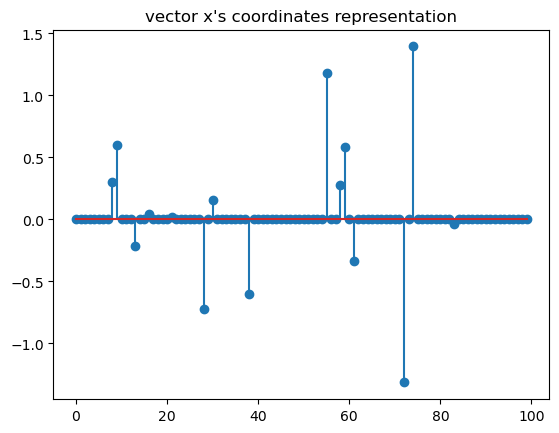

In [5]:
plt.stem(x)
plt.title("vector x's coordinates representation")

## Construction of measurements matrices
We construct various random measurement matrices:  

1) The first one is using some power $p$ of i.i.d. Gaussian random variables: that is when the measurement matrix $A$ is populated with i.i.d. random variables like $${\rm sign}(g) |g|^p$$ where $g$ is a standard Gaussian variable and $p\geq1$ is some power. (Note: for $p=1$, it is a standard Gaussian matrix).

2) The second one are Student variable with degree $p$. That is a random variable absolutly continuous with a density of the order of  $(1+t)^{-(p+1)}$.

In [6]:
def measurement_matrix(m, N, rand_type = "gauss", power = 2):
    if rand_type == "student":
        A = np.random.standard_t(power, size=(m, N))
    else:
        A = np.random.randn(m, N)
        A = np.multiply(np.power(np.absolute(A),power), np.sign(A))          
    return A    

In [7]:
A = measurement_matrix(2, 10, rand_type = "gauss")#, power = 4)

## Basis Pursuit as a linear program
One can recast the Basis Pursuit procedure as a linear program. 

Let $A\in\mathbb{R}^{m\times N}$ be a measurements matrix and $y\in\mathbb{R}^m$ be a measurements vector. We consider the following linear programming problem (LP):


> $$\min_{z^+,z^-\in\bR^N} \sum_{j=1}^n z_i^+ + z_i^-$$

> subject to $$ [A|-A]\left[\begin{array}{c} z^+\\ z^-\end{array}\right] = y \text{ and } \left[\begin{array}{c} z^+\\ z^-\end{array}\right]\geq 0 $$



For any $x\in\R^N$, we denote by  $x^+\in\R^N$ and $x^-\in\R^N$ vectors with coordinates given for any $j=1,\ldots,N$ by

$$
(x^+)_j = \max(0,x_j) \text{ et } (x^-)_j = \max(0,-x_j).
$$

There is equivalence between the Basis Pursuit procedure and (LP) in the following way: 

>	If $\hat x$ is a solution to (BP) then $(\hat x^+, \hat x^-)$ is solution to (LP)

>	If $(\hat z^+, \hat z^-)$ is a solution to (LP) then $\hat z^+-\hat z^-$ is solution to (BP).




# Import cvxopt library for solving linear programming problems

**CVXOPT** is a powerfull library for solving various type of convex optimization problems. For instance, *solvers.cp* solves non-linear convex optimization problems with twices differentiable objective and constraint functions with closed form solutions for the gradient and the Hessian. We refer to examples from <a href="http://cvxopt.org/userguide/solvers.html#problems-with-nonlinear-objectives">Non-linear convex optimization</a>.

Here we are concerned about **Linear Programming** -- that is for convex optimization problems where both the objective and the constraints are linear.

In [8]:
from cvxopt import matrix, solvers, sparse, sparse, spmatrix, spdiag
solvers.options['show_progress'] = False # No logs printed

### matrix objects in cvxopt
cvxopt has its own *matrix* object which is different from the numpy's one

In [9]:
A = matrix([[1,2,3],[4,5,6]])
#print(A, '-'*10, '\n',  A[1,:], '-'*10, '\n', A[::-1,::-1], '-'*10, '\n', A[0:4])
#print('-'*10, '\n', A.size)

In [10]:
A = matrix([1, 2, 3, 4, 5, 6], (2,3))
B = matrix([ [1, 2], [3, 4] ])
C = matrix([ [A] ,[B], [-A]])
D = matrix(range(16),(4,4))
E = matrix(np.ones(5))
F = matrix(np.random.randn(2,3))
G = matrix(np.zeros(2))
#print(A,'-'*10, '\n', B, '-'*10, '\n', C, '-'*10, '\n', D, '-'*10, '\n', E, '-'*10, '\n', F, '-'*10, '\n', G)

In [11]:
A = matrix([[1,2,3],[4,5,6]])
B = np.array(A)
#print(A, '-'*10, '\n', B)

### sparse matrix objects
cvxopti has its own *sparse matrix* object which is different from the scipy's one

In [ ]:
#Try to understand how they proceed:
E = spmatrix([1, 2], [0, 1], [0, 1], (4,2)) #(value, row, column, size)
B = matrix([ [1, 2], [3, 4] ])
F = sparse([ [B, B], [E] ])
G = spdiag([B, -B, 1, 2])
H = spdiag([1]*2)
K = matrix([B, -B])
K2 = matrix([[B], [-B]])
J = matrix([[B,-B, -H],[-B, B, -H]])
#print(E, '-'*30, '\n', F, '-'*30, '\n', G, '-'*30, '\n', H)
#print(K, '-'*30, '\n', K2, '-'*30, '\n', J)

# Linear programming in cvxopt (<a href = 'http://cvxopt.org/userguide/coneprog.html#cvxopt.solvers.conelp'> cvxopt conelp solver </a> and <a href = 'http://cvxopt.org/userguide/coneprog.html#linear-programming'> cvxopt lp solver </a>)
Linear Programming problems in *cvxopt* have the following form
$$\min \inr{c,x} \text{ subject to } Gx + s =h, Ax=b, s\geq 0$$

CVXOPT command to solve this problem is 

> sol = cvxopt.solvers.lp(c, G, h, A = None, b = None, solver = None, primal_start = None, dual_start = None)

> sol = sol['x']

The **solver** argument is used to choose among three solvers. When it is omitted or None, the CVXOPT function **conelp** is used. The external solvers **GLPK** and **MOSEK** (if installed) can be selected by setting solver to 'glpk' or 'mosek'. (cf.  <a href = 'https://scaron.info/blog/linear-programming-in-python-with-cvxopt.html'> Stéphane Caron's webpage </a>)


# Solving (BP) via cvxopt

$\providecommand{\bR}{\mathbb{R}}$

Let $A\in\bR^{m\times N}$ and $y\in\R^m$. (LP) is defined by:

> $$(\hat z^+, \hat z^-)\in\argmin_{(z^+,z^-)\in\bR^{2N}} \sum_{j=1}^n z_i^+ + z_i^-  \text{ subject to } [A|-A]\left[\begin{array}{c} z^+\\ z^-\end{array}\right] = y \text{ and } \left[\begin{array}{c} z^+\\ z^-\end{array}\right]\geq 0 $$

Solution to (BP) is recovered via $t= \hat z^+- \hat z^-$.

We recall that linear Programming problems considered in cvxopt have the following form: 


$$\min \inr{c,x} \text{ subject to } Gx + s =h, Ax=b, s\geq 0.$$

In the case of (LP) -- the equivalent formulation of (BP):

$$c = \left[\begin{array}{c} \1 \\ \1 \end{array}\right]\in\R^{2N};\hspace{1cm} G=-I_{2N}; \hspace{1cm} h = 0\in\R^{2N}; \hspace{1cm} A = [A|-A]\in\R^{m\times 2N};\hspace{1cm} b = y\in\R^m$$

### Construction of cvxopt matrices $c, G, h, A, b$

In [16]:
def cvx_mat(A, y):
    '''A, y: numpy array or cvx matrices
    return parameters c, G, h, A, b for CVXOPT solvers.lp method 
    for our (LP) problem'''
    A = matrix(A)
    y = matrix(y)
    m, N = matrix(A).size
    # matrix c, G, h, A, b
    c = matrix(np.ones(2*N))
    G = -spdiag([1]*2*N)
    h = matrix(np.zeros(2*N))
    A = matrix([[A],[-A]])
    b = y
    return c, G, h, A, b

In [17]:
N, m, s = 100000, 250, 20
A, x = measurement_matrix(m, N), signal(N, s) 
y = np.dot(A,x)
c, G, h, A, b = cvx_mat(A, y)
#print(c, '-'*10, '\n', G,'-'*10, '\n', h,'-'*10, '\n', A,'-'*10, '\n', b)

### cvxopt linear solver  <a href="http://cvxopt.org/examples/tutorial/lp.html"> cvx lp </a>

In [ ]:
#In this cell, we solve a linear system with 100.000 variables and 250: it may take 2 minutes
sol = solvers.lp(c, G, h, A, b)
sol = sol['x']
x_recover = sol[0:N] - sol[N:2*N]

In [19]:
#Reconstruction error for x of size 100.000)
np.linalg.norm(matrix(x) - x_recover,2)

0.31827133053066126

In [20]:
def dist(x, sol):
    N = len(x)
    x_recover = sol[0:N] - sol[N:2*N]
    return np.linalg.norm(matrix(x) - x_recover,2)

In [21]:
N, m, s = 500, 80, 10
A, x = measurement_matrix(m, N), signal(N, s) 
y = np.dot(A,x)
c, G, h, A, b = cvx_mat(A, y)
sol = solvers.lp(c, G, h, A, b)
sol = sol['x']
x_recover = sol[0:N] - sol[N:2*N]
print('erreur ell_2 = {}'.format(dist(x, sol)))

erreur ell_2 = 8.66790096703208e-09


Text(0.5, 1.0, 'reconstruction')

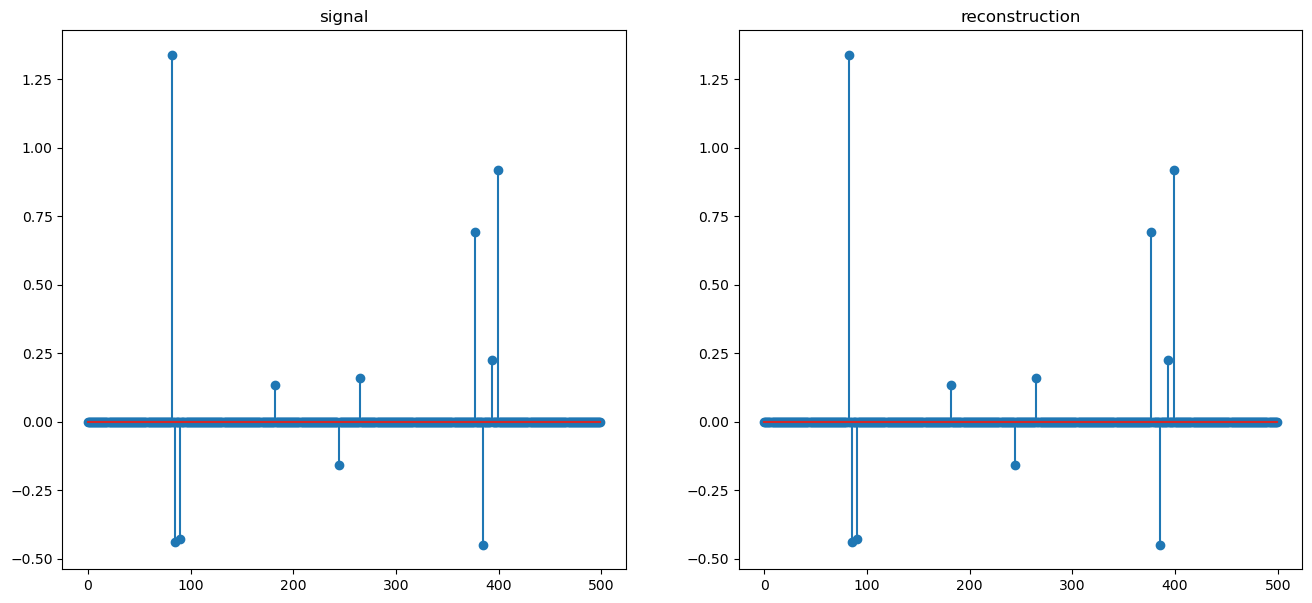

In [22]:
fig, (subfig1,subfig2) = plt.subplots(1,2,figsize=(16,7)) # one figure with two horizontal subfigures
subfig1.stem(x)
subfig1.set_title('signal')
subfig2.stem(x_recover)
subfig2.set_title('reconstruction')

### Performance comparison between solver with and without solver = 'glpk' option

In [23]:
N, m, s = 1000, 200, 30
A, x = measurement_matrix(m, N), signal(N, s) 
y = np.dot(A,x)
c, G, h, A, b = cvx_mat(A, y)

In [ ]:
#For me, it took 522ms per loop (4.2s in total)
%timeit solvers.lp(c, G, h, A, b)

522 ms ± 55.5 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [25]:
# We Suppress CVXOPT's native solver output above with:
#solvers.options['show_progress'] = False

# Now, we also suppress GLPK C-level simplex output:
# 'msg_lev': 'GLP_MSG_OFF' sets GLPK message level to 0 (silent)
solvers.options['glpk'] = {'msg_lev': 'GLP_MSG_OFF'}

In [ ]:
#It took 1.16s per loop for me (9.3 s in total)
%timeit solvers.lp(c, G, h, A, b, solver = 'glpk')

1.16 s ± 17.7 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


# Phase transition diagrams for (BP)

We say that the reconstruction is a success when $||x-x_{recover}||_2\leq 0.001$

In [27]:
def phase_transition_mat(N, nbtest, rand_type = "gauss", power = 2):
    """return a N.N/2 matrix with the number of reconstruction success for every  1\leq m \leq N measurements 
    and sparsity 1\leq sparsity \leq N/2
    N : ambiant dimension of the signals
    nbtest : number of tests for each pixel"""
    PTM = np.zeros((N,int(N/2)))
    set_ind_failure = []
    for m in range(1,N+1):#construct one line of the Phase transition matrix for a given number of measurements m
        if (m % 20) == 0:
            print("line number {} done".format(m))
        M = measurement_matrix(m, N, rand_type, power)
        ind_failure = 0
        for sparsity in range(1,min(m+1, int(N/2))+1):
            nb_success = 0         
            for i in range(nbtest):
                x = signal(N, sparsity)
                y = np.dot(M,x)
                c, G, h, A, b = cvx_mat(M, y)
                sol = solvers.lp(c, G, h, A, b)
                sol = sol['x']
                if dist(x, sol) <= 0.001:
                    nb_success = nb_success + 1
            PTM[m-1, sparsity-1] = nb_success
    return PTM

In [28]:
def frontier(mat, nbtest):
    """construction of the phase transition frontier, i.e. first time the number of success goes below nbtest/2"""
    L = []
    N = len(mat)
    for s in range(int(N/2)):
        P = 0
        while mat[P,s]<nbtest/2 and P<N-1:
            P = P + 1
        L.append(P)
    return L

In [ ]:
#It takes 13mins for N, nbtest = 50, 16. We may start with the smallest size transition matrix
#N, nbtest = 50, 16
N, nbtest = 35, 10
mat = phase_transition_mat(N, nbtest)# construction of the matrix with the number of success among nbtest

line number 20 done
line number 40 done


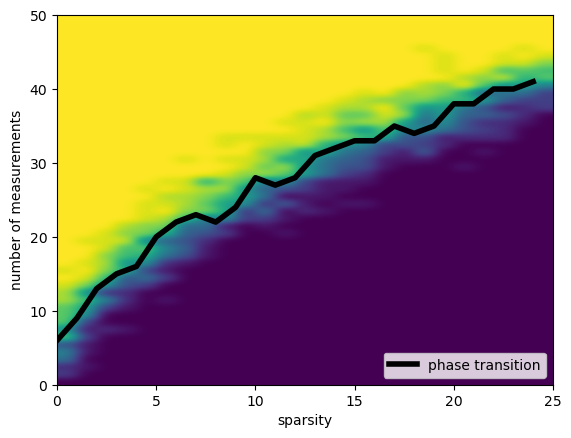

In [30]:
P_min, P_max, S_min, S_max = 0, N, 0, int(N/2)
fig = plt.imshow(mat[P_min:P_max, S_min:S_max], interpolation="gaussian",  
                 aspect='auto', origin = 'lower', extent=[S_min, S_max, P_min, P_max])
plt.xlabel('sparsity')
plt.ylabel('number of measurements')

#empirical phase transition
X = range(int(N/2))
L = frontier(mat, nbtest)
plt.plot(X,L, linewidth=4, color = 'black', label='phase transition')
plt.legend(loc=4)

#filename = 'noisy_gaussian_{}_eps_{}.png'.format(n, eps)
#plt.savefig(filename,bbox_inches='tight')

### Repeat the construction of the frontier *nb_curves* times to "smooth it"

> nb_curves: number of phase transition curves constructed. Those curves are then averaged to "smooth" the effect of randomness in phase transition and get a "stable" phase transition

In [ ]:
#n, eps, nbtest = 100, 0.1, 16
nb_curves = 5
L = np.zeros(int(N/2))
for i in range(nb_curves):
    if (i % 10) == 0:
        print('step {} done'.format(i))
    mat = phase_transition_mat(N, nbtest)
    F = frontier(mat, nbtest)
    L = [sum(a) for a in zip(L,F)] 
L_gauss = [i/nb_curves for i in L]

step 0 done
line number 20 done
line number 40 done
line number 20 done
line number 40 done
line number 20 done
line number 40 done
line number 20 done
line number 40 done

In [403]:
#For next use, save the Gaussian phase transition frontier in a txt file 
#import pickle
#filename = 'phase_transition_diagram_N_{}_nbtest_{}_nbcurves.p'.format(N, nbtest, nb_curves)
#with open(filename, "wb") as f:
#    pickle.dump(L_gauss, f)

#import the phase transition diagram
#filename = 'phase_transition_diagram_N_{}_nbtest_{}_nbcurves.p'
#with open(filename, "rb") as inputfile:
#    L_gauss = pickle.load(inputfile)
#L_gauss = [int(float(ele[0])) for ele in L_gauss]

### Draw the phase transition frontier of the Basis Pursuit procedure (via cvx.lp) for Gaussian measurements

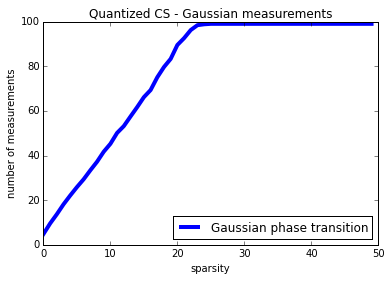

In [ ]:
X = range(len(L_gauss))
plt.plot(X,L_gauss, linewidth=4, color = 'blue', label="Gaussian phase transition")

plt.xlabel('sparsity')
plt.ylabel('number of measurements')
plt.legend(loc=4)
#filename = 'gaussian_phase_transition_quantized_cs_{}_eps_{}.png'.format(n, eps)
#plt.savefig(filename,bbox_inches='tight')

# Measurement matrices used in the proof of the NP-hardness of the $\ell_0$-minimization procedure

NP-hardness of the $\ell_0$-minimization procedure is based on a reduction principle. One can tranform the  NP-complete **cover by $3$-sets problem** into an instance of the $\ell_0$-minimization problem in polynomial time. Proving that $\ell_0$-minimization problem is 'harder' than the cover by $3$-sets problem.

*Cover by $3$-sets problem*: given a collection $\cC=\{C_1, \ldots, C_N\}$ of subsets of $\{1,\ldots,m\}$ all of cardinality $3$, is it possible to answer the question about the existence of a partition of $\{1,\ldots,m\}$ within this collection?

To prove that $\ell_0$-minimization problem can be reduced to the cover by $3$-sets problem, one can consider the following measurement vector
$$
y = \left(
\begin{array}{c}
1\\
1\\
\vdots\\
1\\
\end{array}
\right)
$$
and a measurement matrix:
$$
A=[1_{C_1}| \cdots | 1_{C_N}]
$$
where $1_{C_1}$ is a vector in $\R^m$ such that $(1_{C_1})_i = 1$ if $i\in C_1$ and $0$ if $i\notin C_1$. 

One can see that a solution to the $\ell_0$-minimization procedure $\hat x_0$ obtained from $y$ and $A$ can be used to answer the *cover by $3$-sets problem*: if $\norm{\hat x_0}_0=m/3$ then there is a partition of $\{1,\ldots,m\}$ in the collection $\cC$; if $\norm{\hat x_0}_0>m/3$ then there is no such a partition (note that one can show that necessarily  $\norm{\hat x_0}_0\geq m/3$, hence one of the two cases is true).

Hence solving the $\ell_0$-minimization procedure for this $y$ and $A$ can be reduced in polynomial time to a solution of an NP-complete problem (and so by definition $\ell_0$-minimization is an NP-Hard problem).

## Phase transition of (BP) for the $0-1$ matrix $A$
We construct matrices $A$ introduced in the last paragraph in the two cases: either there is a partition and so the solution of the $\ell_0$-minimization problem should have a support of size $m/3$ either there is no partition and so $\hat x_0$ should have a strictly larger support. 

We want to check the performances of (BP) in this setup. We expect it to fail otherwise this would give a polynomial time algorithm to solve an NP-hard problem.

In [97]:
def measurement_mat_partition(N, m, partition="yes", shuffling="yes"):
    """Construct a binary measurement matrix derived from an Exact Cover by 3-Sets (X3C) instance.

    This function builds an m x N sensing matrix A in {0, 1}^(m x N) where every
    column has exactly three non-zero entries (each column corresponds to a 3-element
    subset of an m-element universe). It is used to demonstrate the NP-hardness
    reduction of l_0-minimization to X3C and to show cases where Basis Pursuit
    (l_1-relaxation) fails to recover the sparsest solution.

    Parameters
    ----------
    N : int
        Total number of columns (number of candidate 3-sets in the collection).
        Must be at least m // 3.
    m : int
        Total number of rows (size of the universe to cover). Must be a multiple of 3.
    partition : {'yes', 'no'}, default='yes'
        Whether the collection of columns contains an exact partition of the m rows:
        - 'yes': Exactly m // 3 columns form an exact partition of {0, ..., m - 1},
          meaning their sum is the all-ones vector 1_m.
        - 'no': No exact partition exists (columns only cover a subset of rows, e.g.,
          leaving the last row uncovered).
    shuffling : {'yes', 'no'}, default='yes'
        Column placement of the exact partition (active only when `partition='yes'`):
        - 'yes': The m // 3 partition columns are uniformly distributed at random
          across the N columns.
        - 'no': The m // 3 partition columns are placed at the first m // 3 columns
          (indices 0 to m // 3 - 1), making x = [1, ..., 1, 0, ..., 0]^T the exact
          canonical sparse ground truth satisfying A x = 1_m.

    Returns
    -------
    A : numpy.ndarray of shape (m, N) and dtype float
        The binary measurement matrix where every column contains exactly three 1s
        and (m - 3) 0s.

    Raises
    ------
    AssertionError
        If `m` is not divisible by 3 or if `N < m // 3`.

    Examples
    --------
    >>> import numpy as np
    >>> A = measurement_mat_partition(
    ...     N=500, m=60, partition="yes", shuffling="no"
    ... )
    >>> x_true = np.zeros(500)
    >>> x_true[:20] = 1.0  # 60 / 3 = 20 columns
    >>> b = A @ x_true
    >>> np.allclose(b, np.ones(60))
    True
"""
    assert m % 3 == 0, f"m ({m}) must be a multiple of 3."
    assert N >= m // 3, f"N ({N}) must be at least m / 3 ({m // 3})."

    A = np.zeros((m, N), dtype=float)
    k_partition = m // 3

    if partition == "yes":
        # Randomly partition rows {0, ..., m-1} into m//3 disjoint triples
        row_perm = np.random.permutation(m)

        # Decide which columns will hold the partition
        if shuffling == "yes":
            col_indices = np.random.choice(N, size=k_partition, replace=False)
        else:
            col_indices = np.arange(k_partition)

        # Place the disjoint triples into the selected columns
        for i, col in enumerate(col_indices):
            triple = row_perm[3 * i : 3 * i + 3]
            A[triple, col] = 1.0

        # Fill the remaining columns with random 3-element subsets of rows
        remaining_cols = np.setdiff1d(np.arange(N), col_indices)
        for col in remaining_cols:
            triple = np.random.choice(m, size=3, replace=False)
            A[triple, col] = 1.0

    else:
        # Guarantee no exact partition exists:
        # e.g., restrict row choices to {0, ..., m-2}, leaving row m-1 with 0 coverage
        for col in range(N):
            triple = np.random.choice(m - 1, size=3, replace=False)
            A[triple, col] = 1.0

    return A

In [103]:
#Sanity check: 
m = 60  # 20 triples * 3 = 60 rows
N = 500  # Total columns

# 1. Unshuffled: partition columns are exactly indices 0 to 19
A = measurement_mat_partition(N, m, partition="yes", shuffling="no")

# The true signal= Vector with 20 ones at the front, 480 zeros
x = np.zeros(N)
x[:20] = 1.0

# Compute product
b = A @ x

print(f"Shape of b: {b.shape}")  # (60,)
print(f"Is b all ones? {np.allclose(b, np.ones(m))}")  # True
print(f"Number of non-zeros in b: {np.count_nonzero(b)}")  # 60
print(f"Do all columns of A have three 1 and all the other are 0? {np.all(np.sum(A == 1, axis=0) == 3)&(np.all(np.sum(A == 0, axis=0) == m-3))}")

Shape of b: (60,)
Is b all ones? True
Number of non-zeros in b: 60
Do all columns of A have three 1 and all the other are 0? True


In [104]:
def measures_vectors(m):
    return np.ones(m)

In [105]:
N, m = 500, 3*20
A = measurement_mat_partition(N, m, partition = 'yes', shuffling ='no') 
y = measures_vectors(m)

<StemContainer object of 3 artists>

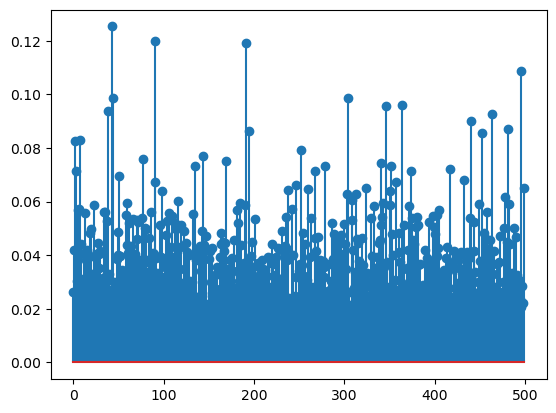

In [106]:
c, G, h, A_cvx, b = cvx_mat(A, y)
sol = solvers.lp(c, G, h, A_cvx, b)
sol = sol['x']
x_recover = sol[0:N] - sol[N:2*N]
plt.stem(x_recover)

Basis Pursuit does not work for this type of $0-1$ valued measurement matrices. Indeed, the target signal is sparse with sparsity $s=20$ (because we asked for the existence of a partition of $\{1, \cdots, m\}$ for $m=3*20$). However, the $\ell_0$-norm (i.e. size of the support) of the reconstructed signal is almost $500$:

In [ ]:
#Size of the support of the reconstructed vector
sum(1 for x in x_recover if abs(x) > 1e-12)

500

In [114]:
# Convert CVXOPT matrix to NumPy and flatten/reshape to match x
diff = np.array(x_recover) - x

# Compute Euclidean (l2) norm: ||x_recover - x||_2
np.linalg.norm(diff)

98.3222076521281

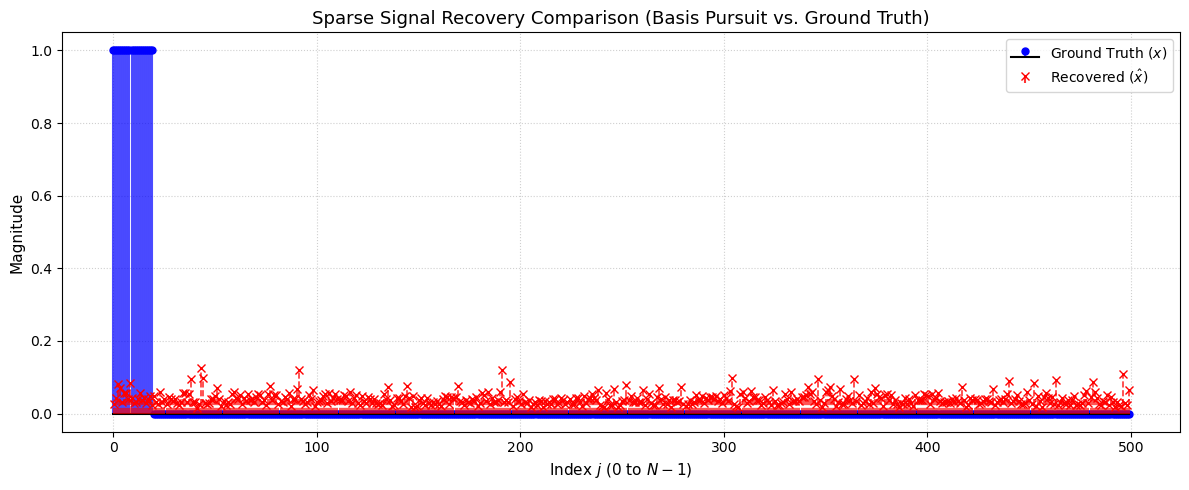

In [115]:
# 1. Ensure both vectors are 1D NumPy arrays
x_arr = np.array(x).ravel()
x_rec_arr = np.array(x_recover).ravel()

N = len(x_arr)
indices = np.arange(N)

# 2. Create the figure
plt.figure(figsize=(12, 5))

# Plot ground truth x (blue stems, solid line)
markerline1, stemlines1, baseline1 = plt.stem(
    indices,
    x_arr,
    linefmt="b-",
    markerfmt="bo",
    basefmt="k-",
    label="Ground Truth ($x$)",
)
plt.setp(stemlines1, linewidth=1.5, alpha=0.7)
plt.setp(markerline1, markersize=5)

# Plot recovered x_recover (red stems, dashed, slightly offset indices for visual distinction)
offset = 0.2
markerline2, stemlines2, baseline2 = plt.stem(
    indices + offset,
    x_rec_arr,
    linefmt="r--",
    markerfmt="rx",
    basefmt="none",
    label="Recovered ($\hat{x}$)",
)
plt.setp(stemlines2, linewidth=1.2, alpha=0.8)
plt.setp(markerline2, markersize=6)

# Formatting
plt.title(
    "Sparse Signal Recovery Comparison (Basis Pursuit vs. Ground Truth)",
    fontsize=13,
)
plt.xlabel("Index $j$ (0 to $N-1$)", fontsize=11)
plt.ylabel("Magnitude", fontsize=11)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.show()